In [1]:
from pathlib import Path
import pandas as pd

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_FILE = ROOT / "data" / "processed" / "nepal_wdi_2010_2024_working.csv"
DICTIONARY_FILE = ROOT / "data" / "metadata" / "variable_dictionary.csv"

df = pd.read_csv(DATA_FILE)
dictionary = pd.read_csv(DICTIONARY_FILE)

indicator_columns = dictionary["Indicator"].tolist()

print("Dataset loaded:", DATA_FILE.resolve())
print("Rows:", len(df))
print("Indicators:", len(indicator_columns))

display(df.head())

Dataset loaded: /Users/zsres/Documents/M.Tech/Statistical-Inference-Assignment/data/processed/nepal_wdi_2010_2024_working.csv
Rows: 15
Indicators: 9


,Year,Country,Country_Code,GDP_per_capita,GDP_growth,Life_expectancy,Basic_drinking_water,Secondary_school_enrollment,Electricity_access,Internet_users,Forest_area,CO2_per_capita_excl_LULUCF
0,2010,Nepal,NPL,721.265221,4.816415,66.772,85.761759,55.589291,68.6,7.9300,42.434112,0.175006
1,2011,Nepal,NPL,742.617253,3.421809,67.123,86.359902,58.993511,67.3,9.0000,42.458528,0.195187
2,2012,Nepal,NPL,775.310578,4.670142,67.364,86.953284,63.141479,75.2,11.1493,42.483014,0.226080
3,2013,Nepal,NPL,801.039061,3.525153,67.598,87.541580,65.493530,77.4,13.3000,42.507429,0.228210
4,2014,Nepal,NPL,846.665542,6.011483,67.812,88.124806,67.531830,84.9,15.4400,42.531915,0.265695


In [2]:
values = df[indicator_columns]

q1 = values.quantile(0.25, interpolation="linear")
q3 = values.quantile(0.75, interpolation="linear")

descriptive = pd.DataFrame({
    "N": values.count(),
    "Mean": values.mean(),
    "Median": values.median(),
    "Min": values.min(),
    "Max": values.max(),
    "Range": values.max() - values.min(),
    "Variance": values.var(ddof=1),
    "SD": values.std(ddof=1),
    "Q1": q1,
    "Q3": q3,
    "IQR": q3 - q1,
})

descriptive.index.name = "Indicator"
descriptive = descriptive.reset_index()

unit_lookup = dictionary.set_index("Indicator")["Unit"]
descriptive.insert(
    1, "Unit", descriptive["Indicator"].map(unit_lookup)
)

TABLE_FILE = ROOT / "results" / "tables" / "descriptive_statistics.csv"
TABLE_FILE.parent.mkdir(parents=True, exist_ok=True)

# Save full precision; round only the displayed table.
descriptive.to_csv(TABLE_FILE, index=False)

display(descriptive.round(4))
print("Saved:", TABLE_FILE.resolve())

,Indicator,Unit,N,Mean,Median,Min,Max,Range,Variance,SD,Q1,Q3,IQR
0,GDP_per_capita,constant 2015 US$ per person,15,947.5189,951.8573,721.2652,1179.9550,458.6898,23203.3875,152.3266,823.8523,1069.9534,246.1011
1,GDP_growth,annual %,15,4.2581,4.6701,-2.3696,8.9773,11.3469,7.8936,2.8096,3.4735,5.8214,2.3479
2,Life_expectancy,years,15,68.5420,68.4440,66.7720,70.6360,3.8640,1.4704,1.2126,67.4860,69.2025,1.7165
3,Basic_drinking_water,% of population,15,89.7884,89.8421,85.7618,93.6401,7.8784,6.3453,2.5190,87.8332,91.7791,3.9459
4,Secondary_school_enrollment,% gross,14,74.2458,73.0929,55.5893,90.3878,34.7986,132.1898,11.4974,66.0031,84.0575,18.0544
5,Electricity_access,% of population,15,85.3000,89.9000,67.3000,97.9000,30.6000,86.9357,9.3239,79.7000,91.0000,11.3000
6,Internet_users,% of population,15,26.4581,24.3000,7.9300,46.3219,38.3919,199.7638,14.1338,14.3700,38.9772,24.6072
7,CO2_per_capita_excl_LULUCF,t CO2e/capita,15,0.3957,0.4712,0.1750,0.5898,0.4147,0.0232,0.1524,0.2457,0.5256,0.2799
8,Forest_area,% of land area,15,42.8789,42.7877,42.4341,43.5973,1.1632,0.1632,0.4040,42.5197,43.1925,0.6728


Saved: /Users/zsres/Documents/M.Tech/Statistical-Inference-Assignment/results/tables/descriptive_statistics.csv


In [3]:
from pathlib import Path
import pandas as pd

ROOT = Path.cwd()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_FILE = (
    ROOT / "data" / "processed"
    / "nepal_wdi_2010_2024_working.csv"
)

nepal = pd.read_csv(DATA_FILE).sort_values("Year").reset_index(drop=True)

TABLE_DIR = ROOT / "results" / "tables"
TABLE_DIR.mkdir(parents=True, exist_ok=True)

print("Loaded from:", DATA_FILE.resolve())
print("Rows, columns:", nepal.shape)

display(nepal.head())

Loaded from: /Users/zsres/Documents/M.Tech/Statistical-Inference-Assignment/data/processed/nepal_wdi_2010_2024_working.csv
Rows, columns: (15, 12)


,Year,Country,Country_Code,GDP_per_capita,GDP_growth,Life_expectancy,Basic_drinking_water,Secondary_school_enrollment,Electricity_access,Internet_users,Forest_area,CO2_per_capita_excl_LULUCF
0,2010,Nepal,NPL,721.265221,4.816415,66.772,85.761759,55.589291,68.6,7.9300,42.434112,0.175006
1,2011,Nepal,NPL,742.617253,3.421809,67.123,86.359902,58.993511,67.3,9.0000,42.458528,0.195187
2,2012,Nepal,NPL,775.310578,4.670142,67.364,86.953284,63.141479,75.2,11.1493,42.483014,0.226080
3,2013,Nepal,NPL,801.039061,3.525153,67.598,87.541580,65.493530,77.4,13.3000,42.507429,0.228210
4,2014,Nepal,NPL,846.665542,6.011483,67.812,88.124806,67.531830,84.9,15.4400,42.531915,0.265695


In [4]:
import numpy as np

# Validate the saved dataset used for analysis.
if nepal["Year"].tolist() != list(range(2010, 2025)):
    raise ValueError("Expected one row per year from 2010 to 2024.")

if not nepal["Country_Code"].eq("NPL").all():
    raise ValueError("Unexpected country in the analysis dataset.")

for column in indicator_columns:
    if not pd.api.types.is_numeric_dtype(nepal[column]):
        raise TypeError(f"{column}: expected numeric data.")

    observed = nepal[column].dropna()

    if observed.empty:
        raise ValueError(f"{column}: no observed values.")

    if not np.isfinite(observed.to_numpy()).all():
        raise ValueError(f"{column}: contains infinite values.")

coverage = pd.DataFrame({
    "N": nepal[indicator_columns].count(),
    "Missing": nepal[indicator_columns].isna().sum(),
})
coverage.index.name = "Indicator"

display(coverage)
coverage.to_csv(TABLE_DIR / "analysis_coverage.csv")

,N,Missing
Indicator,,
GDP_per_capita,15,0
GDP_growth,15,0
Life_expectancy,15,0
Basic_drinking_water,15,0
Secondary_school_enrollment,14,1
Electricity_access,15,0
Internet_users,15,0
CO2_per_capita_excl_LULUCF,15,0
Forest_area,15,0


In [5]:
indicator_columns = [
    "GDP_per_capita",
    "GDP_growth",
    "Life_expectancy",
    "Basic_drinking_water",
    "Secondary_school_enrollment",
    "Electricity_access",
    "Internet_users",
    "CO2_per_capita_excl_LULUCF",
    "Forest_area",
]

units = {
    "GDP_per_capita": "constant 2015 US$ per person",
    "GDP_growth": "annual %",
    "Life_expectancy": "years",
    "Basic_drinking_water": "% of population",
    "Secondary_school_enrollment": "% gross",
    "Electricity_access": "% of population",
    "Internet_users": "% of population",
    "CO2_per_capita_excl_LULUCF": "t CO2e/capita; excluding LULUCF",
    "Forest_area": "% of land area",
}

data = nepal[indicator_columns]

display(data.count().rename("Available_N").to_frame())

,Available_N
GDP_per_capita,15
GDP_growth,15
Life_expectancy,15
Basic_drinking_water,15
Secondary_school_enrollment,14
Electricity_access,15
Internet_users,15
CO2_per_capita_excl_LULUCF,15
Forest_area,15


In [6]:
# Convention: sample variance and SD, denominator N - 1.
# This convention alone does not make annual data a random sample.
DDOF = 1

descriptive = pd.DataFrame({
    "N": data.count(),
    "Mean": data.mean(),
    "Median": data.median(),
    "Minimum": data.min(),
    "Maximum": data.max(),
    "Range": data.max() - data.min(),
    "Variance": data.var(ddof=DDOF),
    "SD": data.std(ddof=DDOF),
    "Q1": data.quantile(0.25, interpolation="linear"),
    "Q3": data.quantile(0.75, interpolation="linear"),
})

descriptive["IQR"] = descriptive["Q3"] - descriptive["Q1"]

descriptive.index.name = "Indicator"
descriptive.insert(
    0,
    "Unit",
    [units[column] for column in descriptive.index],
)

# Save full precision; round only the displayed table.
output_file = TABLE_DIR / "descriptive_statistics.csv"
descriptive.to_csv(output_file)

display(
    descriptive.style.format(
        {
            column: ("{:.0f}" if column == "N" else "{:.3f}")
            for column in descriptive.columns
            if column != "Unit"
        },
        na_rep="Missing",
    )
)

print("Saved:", output_file.resolve())

,Unit,N,Mean,Median,Minimum,Maximum,Range,Variance,SD,Q1,Q3,IQR
Indicator,,,,,,,,,,,,
GDP_per_capita,constant 2015 US$ per person,15,947.519,951.857,721.265,1179.955,458.690,23203.388,152.327,823.852,1069.953,246.101
GDP_growth,annual %,15,4.258,4.670,-2.370,8.977,11.347,7.894,2.810,3.473,5.821,2.348
Life_expectancy,years,15,68.542,68.444,66.772,70.636,3.864,1.470,1.213,67.486,69.203,1.717
Basic_drinking_water,% of population,15,89.788,89.842,85.762,93.640,7.878,6.345,2.519,87.833,91.779,3.946
Secondary_school_enrollment,% gross,14,74.246,73.093,55.589,90.388,34.799,132.190,11.497,66.003,84.057,18.054
Electricity_access,% of population,15,85.300,89.900,67.300,97.900,30.600,86.936,9.324,79.700,91.000,11.300
Internet_users,% of population,15,26.458,24.300,7.930,46.322,38.392,199.764,14.134,14.370,38.977,24.607
CO2_per_capita_excl_LULUCF,t CO2e/capita; excluding LULUCF,15,0.396,0.471,0.175,0.590,0.415,0.023,0.152,0.246,0.526,0.280
Forest_area,% of land area,15,42.879,42.788,42.434,43.597,1.163,0.163,0.404,42.520,43.192,0.673


Saved: /Users/zsres/Documents/M.Tech/Statistical-Inference-Assignment/results/tables/descriptive_statistics.csv


In [7]:
selected = [
    "GDP_per_capita",
    "GDP_growth",
    "Internet_users",
]

display(descriptive.loc[selected].round(3))

extreme_rows = []

for column in selected:
    observed = nepal[["Year", column]].dropna(subset=[column])

    minimum = observed[column].min()
    maximum = observed[column].max()

    extreme_rows.append({
        "Indicator": column,
        "Minimum": minimum,
        "Minimum_years": ", ".join(
            observed.loc[
                observed[column].eq(minimum), "Year"
            ].astype(str)
        ),
        "Maximum": maximum,
        "Maximum_years": ", ".join(
            observed.loc[
                observed[column].eq(maximum), "Year"
            ].astype(str)
        ),
    })

extremes = pd.DataFrame(extreme_rows)

display(extremes.round(3))

extremes.to_csv(
    TABLE_DIR / "selected_indicator_extremes.csv",
    index=False,
)

,Unit,N,Mean,Median,Minimum,Maximum,Range,Variance,SD,Q1,Q3,IQR
Indicator,,,,,,,,,,,,
GDP_per_capita,constant 2015 US$ per person,15,947.519,951.857,721.265,1179.955,458.690,23203.388,152.327,823.852,1069.953,246.101
GDP_growth,annual %,15,4.258,4.670,-2.370,8.977,11.347,7.894,2.810,3.473,5.821,2.348
Internet_users,% of population,15,26.458,24.300,7.930,46.322,38.392,199.764,14.134,14.370,38.977,24.607


,Indicator,Minimum,Minimum_years,Maximum,Maximum_years
0,GDP_per_capita,721.265,2010,1179.955,2024
1,GDP_growth,-2.370,2020,8.977,2017
2,Internet_users,7.930,2010,46.322,2024


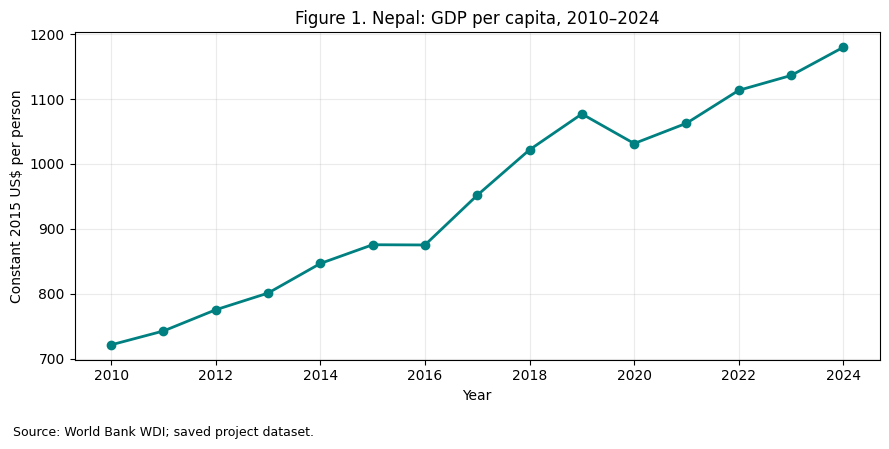

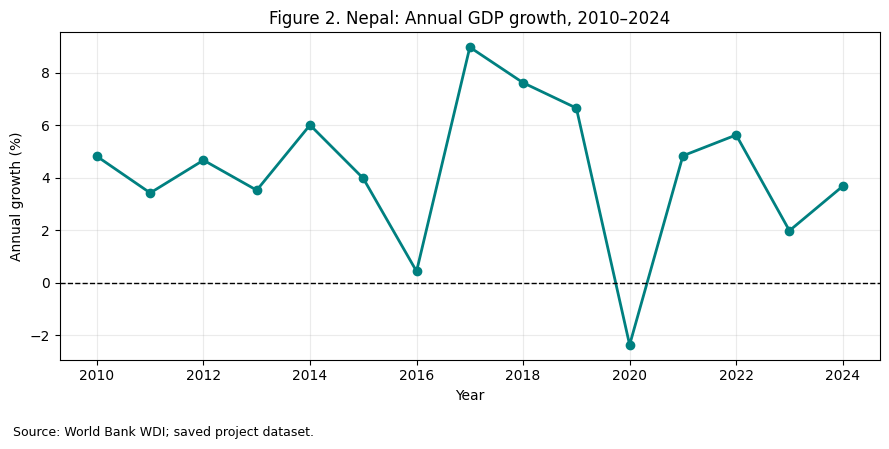

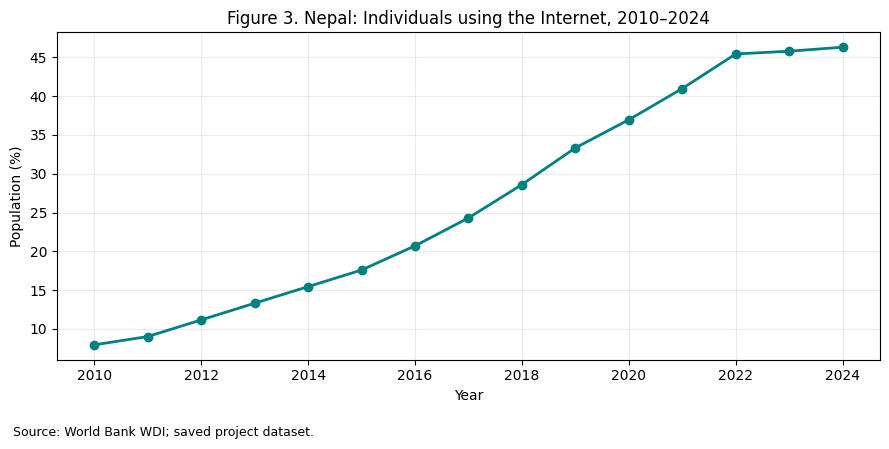

In [8]:
import matplotlib.pyplot as plt

FIGURE_DIR = ROOT / "results" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

plot_specs = [
    ("GDP_per_capita", "GDP per capita",
     "Constant 2015 US$ per person"),

    ("GDP_growth", "Annual GDP growth",
     "Annual growth (%)"),

    ("Internet_users", "Individuals using the Internet",
     "Population (%)"),
]

for figure_number, (column, title, ylabel) in enumerate(
    plot_specs, start=1
):
    # Reindexing preserves gaps if a year or value is missing.
    series = (
        nepal.set_index("Year")[column]
        .reindex(range(2010, 2025))
    )

    fig, ax = plt.subplots(figsize=(9, 4.5))

    ax.plot(
        series.index,
        series.values,
        marker="o",
        linewidth=2,
        color="teal",
    )

    ax.set_title(
        f"Figure {figure_number}. Nepal: {title}, 2010–2024"
    )
    ax.set_xlabel("Year")
    ax.set_ylabel(ylabel)
    ax.set_xticks(range(2010, 2025, 2))
    ax.grid(alpha=0.25)

    if column == "GDP_growth":
        ax.axhline(0, color="black", linewidth=1, linestyle="--")

    fig.text(
        0.02, 0.02,
        "Source: World Bank WDI; saved project dataset.",
        fontsize=9,
    )

    fig.tight_layout(rect=[0, 0.06, 1, 1])

    fig.savefig(
        FIGURE_DIR / f"figure_{figure_number:02d}_{column}.png",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

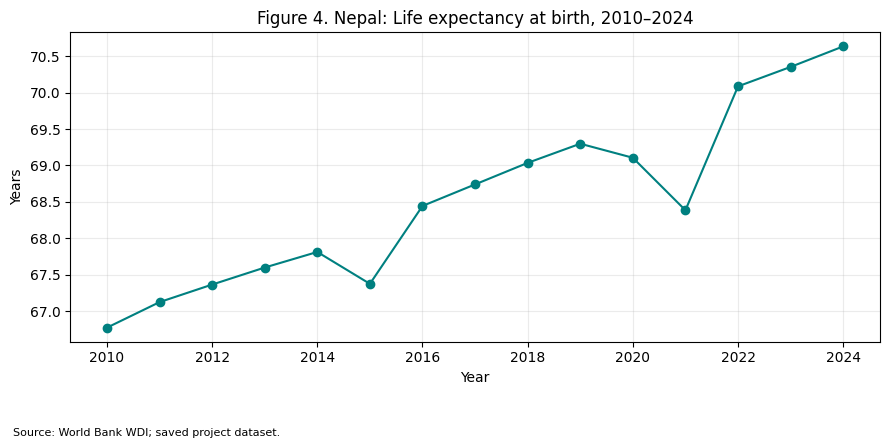

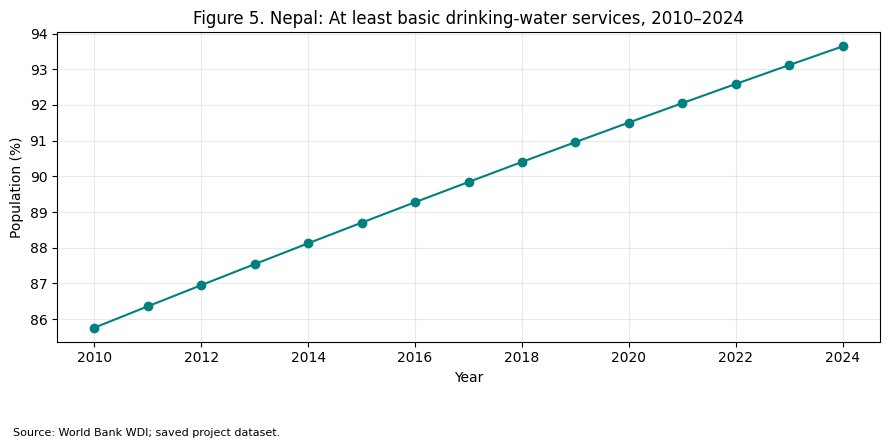

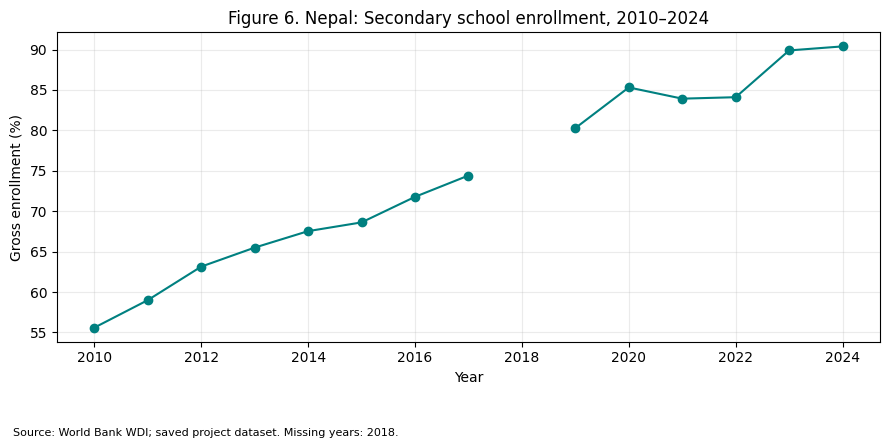

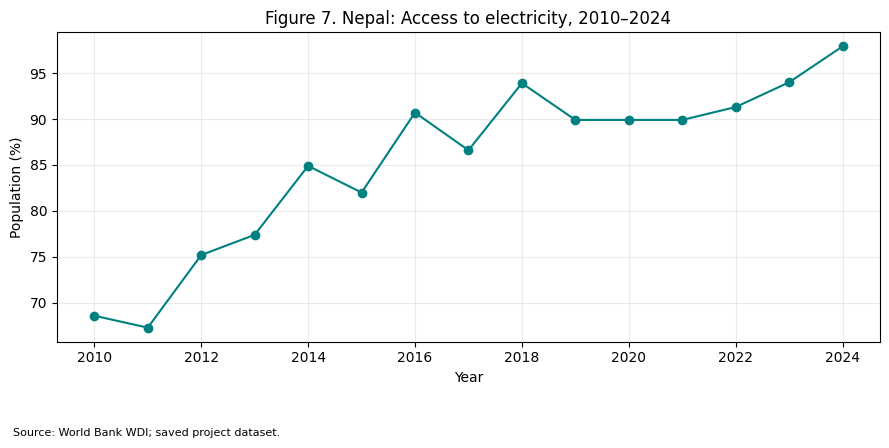

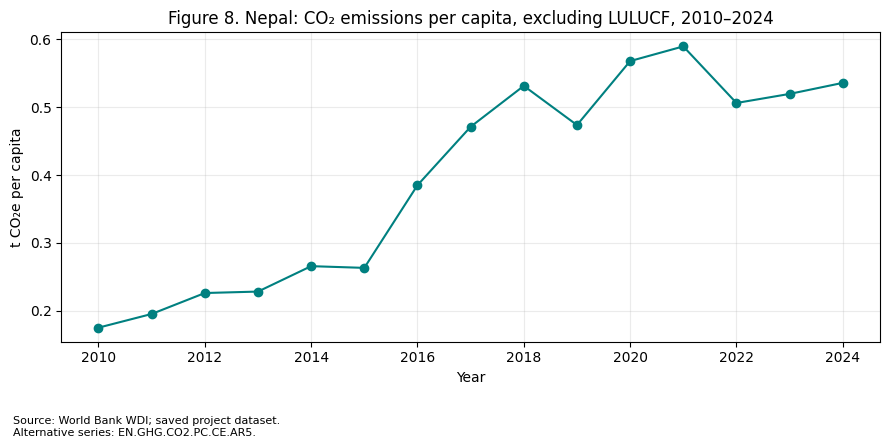

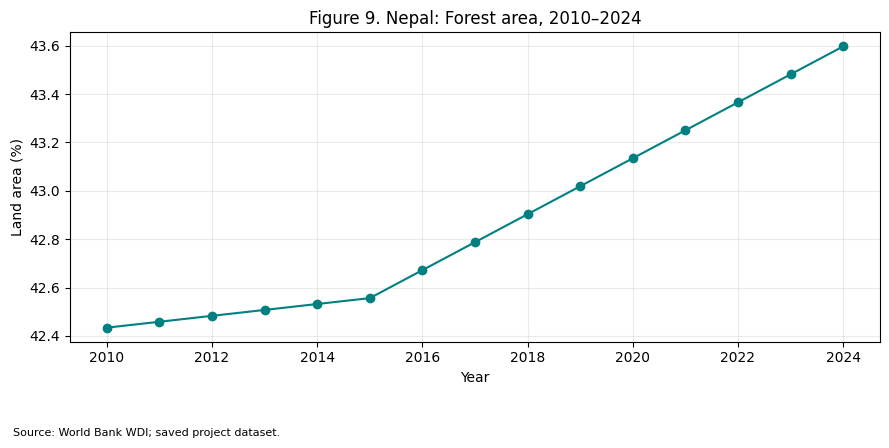

In [9]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

FIGURE_DIR = ROOT / "results" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

remaining_specs = [
    ("Life_expectancy", "Life expectancy at birth", "Years"),
    ("Basic_drinking_water", "At least basic drinking-water services",
     "Population (%)"),
    ("Secondary_school_enrollment", "Secondary school enrollment",
     "Gross enrollment (%)"),
    ("Electricity_access", "Access to electricity", "Population (%)"),
    ("CO2_per_capita_excl_LULUCF", "CO₂ emissions per capita, excluding LULUCF",
     "t CO₂e per capita"),
    ("Forest_area", "Forest area", "Land area (%)"),
]

for number, (column, title, ylabel) in enumerate(remaining_specs, start=4):
    series = (
        nepal.set_index("Year")[column]
        .reindex(range(2010, 2025))
    )

    fig, ax = plt.subplots(figsize=(9, 4.5))

    ax.plot(series.index, series.values, marker="o", color="teal")
    ax.set(
        title=f"Figure {number}. Nepal: {title}, 2010–2024",
        xlabel="Year",
        ylabel=ylabel,
    )
    ax.set_xticks(range(2010, 2025, 2))
    ax.ticklabel_format(axis="y", style="plain", useOffset=False)
    ax.grid(alpha=0.25)

    missing_years = series.index[series.isna()].tolist()
    note = "Source: World Bank WDI; saved project dataset."

    if missing_years:
        note += " Missing years: " + ", ".join(map(str, missing_years)) + "."

    if column == "CO2_per_capita_excl_LULUCF":
        note += "\nAlternative series: EN.GHG.CO2.PC.CE.AR5."

    fig.text(0.02, 0.02, note, fontsize=8)
    fig.tight_layout(rect=[0, 0.10, 1, 1])

    fig.savefig(
        FIGURE_DIR / f"figure_{number:02d}_{column}.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

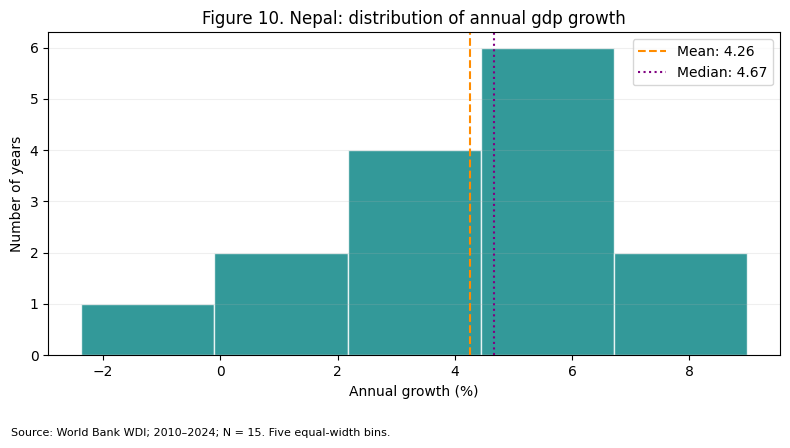

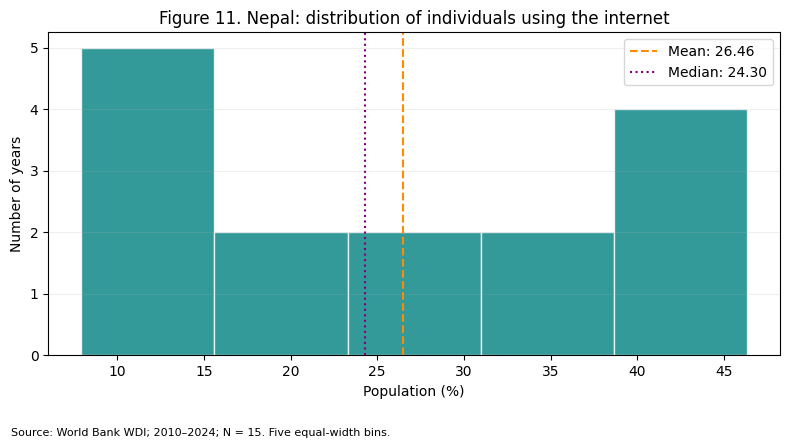

In [10]:
distribution_specs = [
    ("GDP_growth", "Annual GDP growth", "Annual growth (%)"),
    ("Internet_users", "Individuals using the Internet", "Population (%)"),
]

for number, (column, title, xlabel) in enumerate(
    distribution_specs, start=10
):
    values = nepal[column].dropna()

    fig, ax = plt.subplots(figsize=(8, 4.5))

    ax.hist(
        values,
        bins=5,
        color="teal",
        edgecolor="white",
        alpha=0.8,
    )

    ax.axvline(
        values.mean(), color="darkorange",
        linestyle="--", label=f"Mean: {values.mean():.2f}"
    )
    ax.axvline(
        values.median(), color="purple",
        linestyle=":", label=f"Median: {values.median():.2f}"
    )

    ax.set(
        title=f"Figure {number}. Nepal: distribution of {title.lower()}",
        xlabel=xlabel,
        ylabel="Number of years",
    )
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.legend()
    ax.grid(axis="y", alpha=0.2)

    fig.text(
        0.02, 0.02,
        f"Source: World Bank WDI; 2010–2024; N = {len(values)}. "
        "Five equal-width bins.",
        fontsize=8,
    )
    fig.tight_layout(rect=[0, 0.07, 1, 1])

    fig.savefig(
        FIGURE_DIR / f"figure_{number:02d}_histogram_{column}.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

In [11]:
heterogeneity_columns = [
    "GDP_per_capita",
    "Life_expectancy",
    "Internet_users",
    "Forest_area",
]

heterogeneity = descriptive.loc[
    heterogeneity_columns,
    ["Unit", "N", "Mean", "Variance", "SD", "Range", "IQR"],
].copy()

heterogeneity["CV_percent"] = (
    heterogeneity["SD"] / heterogeneity["Mean"] * 100
)

display(heterogeneity.round(4))

heterogeneity.to_csv(
    TABLE_DIR / "heterogeneity_comparison.csv"
)

# Rank 1 = largest numerical spread.
# Raw-measure rankings are shown only to examine scale effects.
measures = ["Variance", "SD", "Range", "IQR", "CV_percent"]

spread_ranks = heterogeneity[measures].rank(
    ascending=False,
    method="min",
)

display(spread_ranks)

spread_ranks.to_csv(
    TABLE_DIR / "heterogeneity_measure_ranks.csv"
)

,Unit,N,Mean,Variance,SD,Range,IQR,CV_percent
Indicator,,,,,,,,
GDP_per_capita,constant 2015 US$ per person,15,947.5189,23203.3875,152.3266,458.6898,246.1011,16.0764
Life_expectancy,years,15,68.5420,1.4704,1.2126,3.8640,1.7165,1.7692
Internet_users,% of population,15,26.4581,199.7638,14.1338,38.3919,24.6072,53.4195
Forest_area,% of land area,15,42.8789,0.1632,0.4040,1.1632,0.6728,0.9422


,Variance,SD,Range,IQR,CV_percent
Indicator,,,,,
GDP_per_capita,1.0,1.0,1.0,1.0,2.0
Life_expectancy,3.0,3.0,3.0,3.0,3.0
Internet_users,2.0,2.0,2.0,2.0,1.0
Forest_area,4.0,4.0,4.0,4.0,4.0


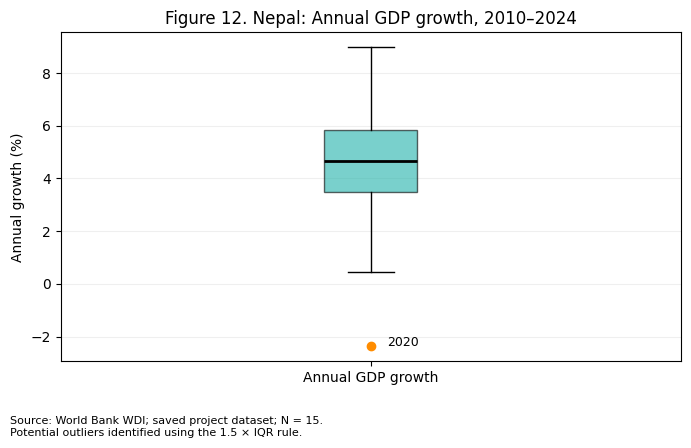

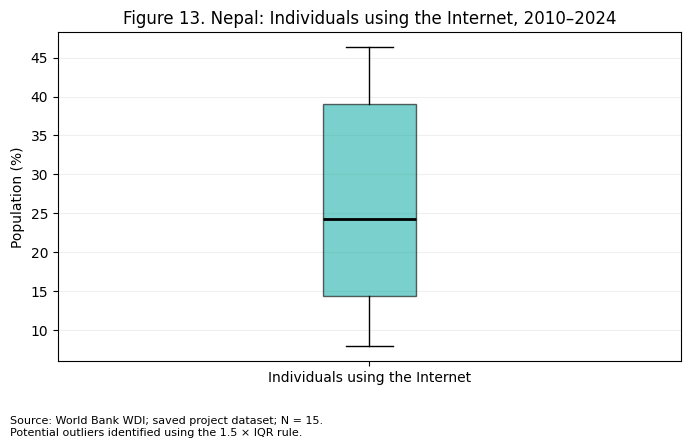

,Indicator,N,Q1,Median,Q3,IQR,Lower_fence,Upper_fence,Potential_outlier_N,Potential_outlier_years
0,GDP_growth,15,3.473,4.67,5.821,2.348,-0.048,9.343,1,2020
1,Internet_users,15,14.370,24.30,38.977,24.607,-22.541,75.888,0,None


In [12]:
import matplotlib.pyplot as plt

FIGURE_DIR = ROOT / "results" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

boxplot_specs = [
    ("GDP_growth", "Annual GDP growth", "Annual growth (%)"),
    ("Internet_users", "Individuals using the Internet", "Population (%)"),
]

outlier_rows = []

for number, (column, title, ylabel) in enumerate(
    boxplot_specs, start=12
):
    values = nepal[column].dropna()

    # Quartiles and middle 50% spread.
    q1 = values.quantile(0.25, interpolation="linear")
    q3 = values.quantile(0.75, interpolation="linear")
    iqr = q3 - q1

    # Boundaries used to flag potential outliers.
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr

    flagged = nepal.loc[
        nepal[column].lt(lower_fence)
        | nepal[column].gt(upper_fence),
        ["Year", column],
    ]

    outlier_rows.append({
        "Indicator": column,
        "N": len(values),
        "Q1": q1,
        "Median": values.median(),
        "Q3": q3,
        "IQR": iqr,
        "Lower_fence": lower_fence,
        "Upper_fence": upper_fence,
        "Potential_outlier_N": len(flagged),
        "Potential_outlier_years": (
            ", ".join(flagged["Year"].astype(str)) or "None"
        ),
    })

    fig, ax = plt.subplots(figsize=(7, 4.5))

    ax.boxplot(
        values.to_numpy(),
        whis=1.5,
        patch_artist=True,
        boxprops={"facecolor": "lightseagreen", "alpha": 0.6},
        medianprops={"color": "black", "linewidth": 2},
        flierprops={
            "marker": "o",
            "markerfacecolor": "darkorange",
            "markeredgecolor": "darkorange",
        },
    )

    # Label potential outliers with their observation year.
    for _, row in flagged.iterrows():
        ax.annotate(
            str(int(row["Year"])),
            xy=(1, row[column]),
            xytext=(12, 0),
            textcoords="offset points",
            fontsize=9,
        )

    ax.set_xticks([1])
    ax.set_xticklabels([title])
    ax.set_ylabel(ylabel)
    ax.set_title(f"Figure {number}. Nepal: {title}, 2010–2024")
    ax.grid(axis="y", alpha=0.2)

    fig.text(
        0.02, 0.02,
        f"Source: World Bank WDI; saved project dataset; N = {len(values)}.\n"
        "Potential outliers identified using the 1.5 × IQR rule.",
        fontsize=8,
    )

    fig.tight_layout(rect=[0, 0.10, 1, 1])

    fig.savefig(
        FIGURE_DIR / f"figure_{number:02d}_boxplot_{column}.png",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

outlier_summary = pd.DataFrame(outlier_rows)

display(outlier_summary.round(3))

outlier_summary.to_csv(
    TABLE_DIR / "boxplot_outlier_summary.csv",
    index=False,
)

In [13]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_FILE = (
    ROOT / "data" / "processed"
    / "nepal_wdi_2010_2024_working.csv"
)

nepal = pd.read_csv(DATA_FILE).sort_values("Year")

TABLE_DIR = ROOT / "results" / "tables"
FIGURE_DIR = ROOT / "results" / "figures"

TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Loaded:", DATA_FILE.resolve())
display(nepal.head())

Loaded: /Users/zsres/Documents/M.Tech/Statistical-Inference-Assignment/data/processed/nepal_wdi_2010_2024_working.csv


,Year,Country,Country_Code,GDP_per_capita,GDP_growth,Life_expectancy,Basic_drinking_water,Secondary_school_enrollment,Electricity_access,Internet_users,Forest_area,CO2_per_capita_excl_LULUCF
0,2010,Nepal,NPL,721.265221,4.816415,66.772,85.761759,55.589291,68.6,7.9300,42.434112,0.175006
1,2011,Nepal,NPL,742.617253,3.421809,67.123,86.359902,58.993511,67.3,9.0000,42.458528,0.195187
2,2012,Nepal,NPL,775.310578,4.670142,67.364,86.953284,63.141479,75.2,11.1493,42.483014,0.226080
3,2013,Nepal,NPL,801.039061,3.525153,67.598,87.541580,65.493530,77.4,13.3000,42.507429,0.228210
4,2014,Nepal,NPL,846.665542,6.011483,67.812,88.124806,67.531830,84.9,15.4400,42.531915,0.265695


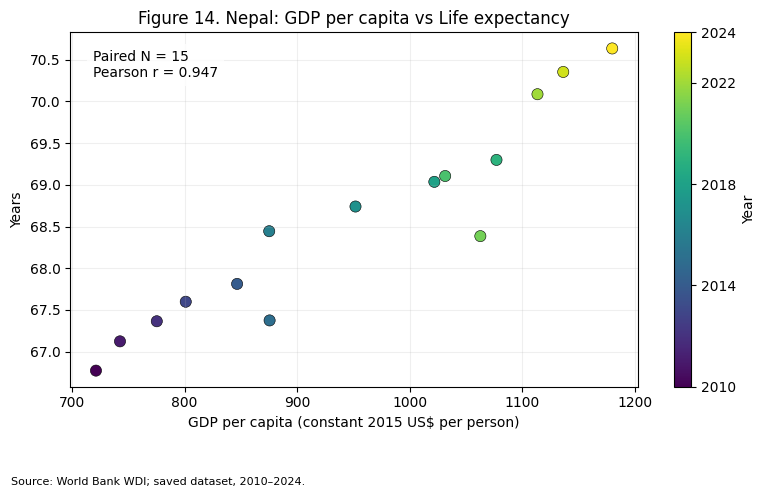

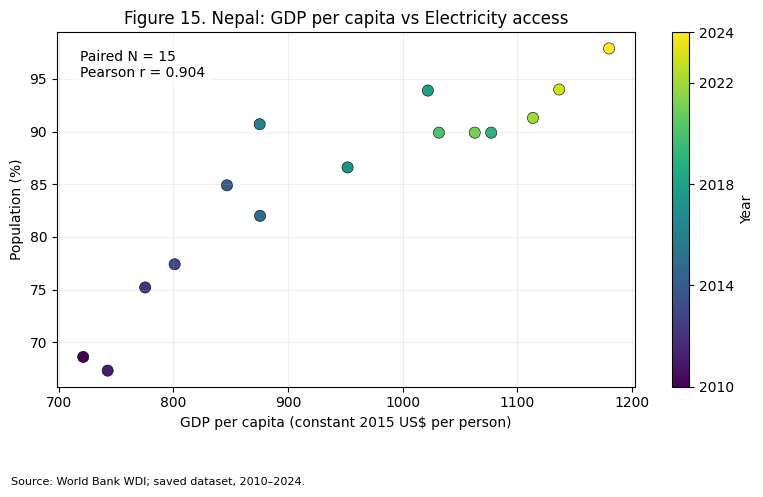

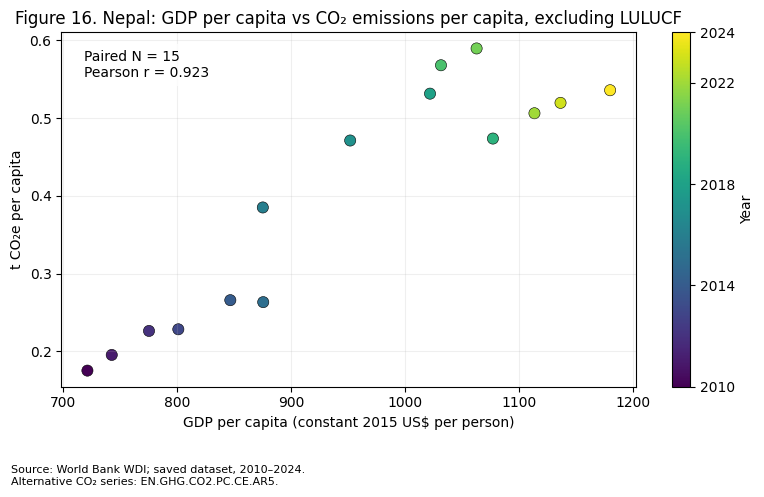

,X,Y,Paired_N,Excluded_years,Sample_covariance,Covariance_unit,Pearson_r
0,GDP_per_capita,Life_expectancy,15,None,174.8354,(constant 2015 US$ per person) × (Years),0.9465
1,GDP_per_capita,Electricity_access,15,None,1284.0841,(constant 2015 US$ per person) × (Population (%)),0.9041
2,GDP_per_capita,CO2_per_capita_excl_LULUCF,15,None,21.4271,(constant 2015 US$ per person) × (t CO₂e per c...,0.9229


In [14]:
pairs = [
    ("Life_expectancy", "Life expectancy", "Years"),
    ("Electricity_access", "Electricity access", "Population (%)"),
    (
        "CO2_per_capita_excl_LULUCF",
        "CO₂ emissions per capita, excluding LULUCF",
        "t CO₂e per capita",
    ),
]

rows = []

for number, (column, label, ylabel) in enumerate(pairs, start=14):
    # Use only years where BOTH indicators are available.
    paired = nepal[["Year", "GDP_per_capita", column]].dropna(
        subset=["GDP_per_capita", column]
    )

    x = paired["GDP_per_capita"]
    y = paired[column]

    covariance = x.cov(y, ddof=1)
    correlation = x.corr(y, method="pearson")

    rows.append({
        "X": "GDP_per_capita",
        "Y": column,
        "Paired_N": len(paired),
        "Excluded_years": ", ".join(
            nepal.loc[
                nepal["GDP_per_capita"].isna() | nepal[column].isna(),
                "Year",
            ].astype(str)
        ) or "None",
        "Sample_covariance": covariance,
        "Covariance_unit": f"(constant 2015 US$ per person) × ({ylabel})",
        "Pearson_r": correlation,
    })

    fig, ax = plt.subplots(figsize=(8, 5))

    points = ax.scatter(
        x, y,
        c=paired["Year"],
        cmap="viridis",
        vmin=2010,
        vmax=2024,
        s=65,
        edgecolors="black",
        linewidths=0.4,
    )

    colourbar = fig.colorbar(points, ax=ax)
    colourbar.set_label("Year")
    colourbar.set_ticks([2010, 2014, 2018, 2022, 2024])

    ax.set(
        title=f"Figure {number}. Nepal: GDP per capita vs {label}",
        xlabel="GDP per capita (constant 2015 US$ per person)",
        ylabel=ylabel,
    )

    ax.text(
        0.04, 0.95,
        f"Paired N = {len(paired)}\nPearson r = {correlation:.3f}",
        transform=ax.transAxes,
        va="top",
        bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none"},
    )
    ax.grid(alpha=0.2)

    note = "Source: World Bank WDI; saved dataset, 2010–2024."
    if column == "CO2_per_capita_excl_LULUCF":
        note += "\nAlternative CO₂ series: EN.GHG.CO2.PC.CE.AR5."

    fig.text(0.02, 0.02, note, fontsize=8)
    fig.tight_layout(rect=[0, 0.10, 1, 1])

    fig.savefig(
        FIGURE_DIR / f"figure_{number:02d}_scatter_GDP_vs_{column}.png",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

correlation_summary = pd.DataFrame(rows)

display(correlation_summary.round(4))

correlation_summary.to_csv(
    TABLE_DIR / "correlation_summary.csv",
    index=False,
)

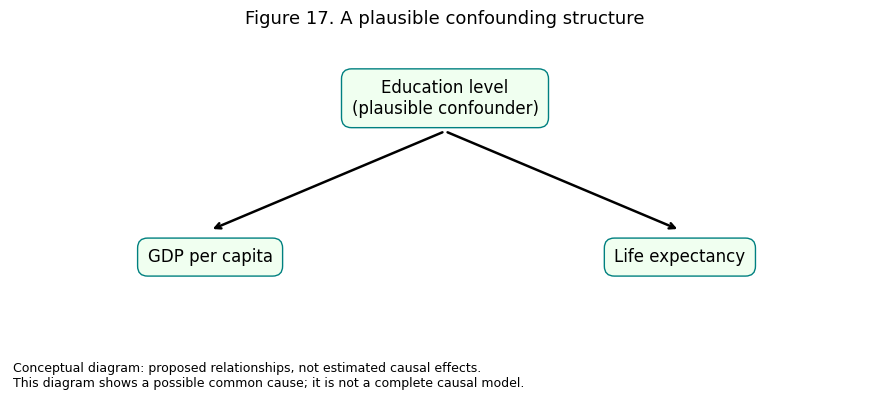

In [15]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 4))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")

positions = {
    "Education level\n(plausible confounder)": (0.50, 0.78),
    "GDP per capita": (0.23, 0.25),
    "Life expectancy": (0.77, 0.25),
}

for label, position in positions.items():
    ax.text(
        *position,
        label,
        ha="center",
        va="center",
        fontsize=12,
        bbox={
            "boxstyle": "round,pad=0.6",
            "facecolor": "honeydew",
            "edgecolor": "teal",
        },
    )

for endpoint in [(0.23, 0.34), (0.77, 0.34)]:
    ax.annotate(
        "",
        xy=endpoint,
        xytext=(0.50, 0.67),
        arrowprops={"arrowstyle": "->", "linewidth": 1.8},
    )

ax.set_title(
    "Figure 17. A plausible confounding structure",
    fontsize=13,
)

fig.text(
    0.02, 0.02,
    "Conceptual diagram: proposed relationships, not estimated causal effects.\n"
    "This diagram shows a possible common cause; it is not a complete causal model.",
    fontsize=9,
)

fig.tight_layout(rect=[0, 0.12, 1, 1])

fig.savefig(
    FIGURE_DIR / "figure_17_confounding_diagram.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

In [16]:
growth = nepal["GDP_growth"].dropna()

q1 = growth.quantile(0.25, interpolation="linear")
q3 = growth.quantile(0.75, interpolation="linear")
iqr = q3 - q1

lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

unusual_observation = nepal.loc[
    nepal["Year"].between(2018, 2022),
    ["Year", "GDP_growth"],
].copy()

unusual_observation["Lower_fence"] = lower_fence
unusual_observation["Upper_fence"] = upper_fence

unusual_observation["Potential_outlier"] = (
    unusual_observation["GDP_growth"].lt(lower_fence)
    | unusual_observation["GDP_growth"].gt(upper_fence)
)

display(unusual_observation.round(3))

unusual_observation.to_csv(
    TABLE_DIR / "unusual_observation_GDP_growth_2020.csv",
    index=False,
)

,Year,GDP_growth,Lower_fence,Upper_fence,Potential_outlier
8,2018,7.622,-0.048,9.343,False
9,2019,6.657,-0.048,9.343,False
10,2020,-2.370,-0.048,9.343,True
11,2021,4.838,-0.048,9.343,False
12,2022,5.631,-0.048,9.343,False


In [17]:
import numpy as np
import pandas as pd

inference_columns = [
    "GDP_growth",
    "Life_expectancy",
]

inference_rows = []

for column in inference_columns:
    values = nepal[column].dropna()

    n = len(values)
    mean = values.mean()
    sample_sd = values.std(ddof=1)

    # Valid as a mean SE only under suitable independence
    # and common-distribution assumptions.
    se_iid = sample_sd / np.sqrt(n)

    inference_rows.append({
        "Indicator": column,
        "N": n,
        "Mean": mean,
        "Sample_SD": sample_sd,
        "SE_under_IID_assumption": se_iid,
        "Population_sigma_known": False,
        "Status": "Preparation only; inferential method pending",
    })

inference_preparation = pd.DataFrame(inference_rows)

display(inference_preparation.round(4))

inference_preparation.to_csv(
    TABLE_DIR / "inference_preparation.csv",
    index=False,
)

,Indicator,N,Mean,Sample_SD,SE_under_IID_assumption,Population_sigma_known,Status
0,GDP_growth,15,4.2581,2.8096,0.7254,False,Preparation only; inferential method pending
1,Life_expectancy,15,68.5420,1.2126,0.3131,False,Preparation only; inferential method pending
